# 11 · Exploración del ángulo coronal: qué hay detrás de los resultados del cuaderno 10

## Propósito

El cuaderno 10 ejecutó el análisis registrado en OSF y dejó varias preguntas que sus resultados, por sí solos, no permiten responder. Este cuaderno las explora a partir de las tablas ya calculadas, sin volver a ejecutar el script de medición ni los segmentadores.

Los análisis de este cuaderno son exploratorios. Las preguntas surgieron después de observar los resultados, por lo que sus respuestas sirven para orientar decisiones posteriores, no para confirmar hipótesis planteadas de antemano. Si alguno de estos hallazgos lleva a modificar la definición de la medida o los criterios de selección, el cambio deberá registrarse antes del estudio en el que se evalúe.

## Preguntas que explora

| Pregunta | Sección |
|---|---|
| ¿Los ángulos más altos de Mendeley cuyos informes no mencionan escoliosis corresponden a curvas visibles o a errores de segmentación? | Revisión visual de los ángulos más altos |
| ¿Qué discos forman el par que determina el ángulo máximo? ¿Cuánto influyen los discos torácicos o cervicales incluidos en el campo de visión? ¿Explican la diferencia entre RSNA y Mendeley? | El par elegido y el ángulo lumbar |
| ¿Qué marcas de calidad aparecen con mayor frecuencia en los estudios con ángulos grandes? | Marcas y curvatura |
| ¿El uso de un *spline* cúbico suavizado mejora el estimador basado en centroides? | Spline frente a diferencias centrales |

## Alcance

Se utilizan los mismos conjuntos, máscaras, planos y centroides del cuaderno 10. La fórmula principal es el eje lateral proyectado y se conserva la regla de selección de pares del artículo, salvo cuando se indica expresamente otra cosa.

Al igual que en el cuaderno 10, los resultados individuales de RSNA se mantienen en una carpeta privada. Los archivos publicables contienen únicamente sus resultados agregados. Las figuras de la revisión visual corresponden exclusivamente a Mendeley, cuyos datos se distribuyen bajo licencia CC BY 4.0.

Este análisis no constituye una validación clínica y no está destinado al diagnóstico de escoliosis.

## Decisiones tomadas antes de ejecutar el cuaderno

Para el ángulo lumbar se incluyeron los discos identificados por TotalSpineSeg con las etiquetas 91 a 96 y 100. Esto comprende T12-L1, los niveles lumbares consecutivos, L5-L6 y L5-S. Se incluye T12-L1 porque su cara inferior es la que toca el platillo superior de L1, de modo que sin ese disco no se podría medir una curva que empiece en L1, y se incluye L5-L6 para que las columnas con una sexta vértebra lumbar conserven su último nivel.

La revisión visual comprende las 20 series T1 de Mendeley con los ángulos más altos entre aquellas cuyos informes no mencionan escoliosis. El *spline* se ajusta mediante `make_smoothing_spline` de SciPy, que selecciona el parámetro de suavizado por validación cruzada generalizada. Las tangentes se evalúan en las mismas vértebras interiores utilizadas por el estimador de diferencias centrales, sin incluir los extremos.

## Fuentes

- Tablas privadas del cuaderno 10: ángulos por serie, planos por cara, centroides por vértebra y marcas por serie y por estudio, almacenadas en `content/datos/analisis_10/`.
- Tablas privadas del cuaderno 09: selección final y traducción de las etiquetas de TotalSpineSeg a la numeración de SPIDER, almacenadas en `content/datos/analisis_09/`, además de las máscaras traducidas en `content/datos/segmentacion_tss/traducidas/`.
- Notas de los radiólogos de Mendeley del cuaderno 08 ([doi:10.17632/s6bgczr8s2.2](https://doi.org/10.17632/s6bgczr8s2.2)), con licencia CC BY 4.0.
- Dependencias: [DIAGNijmegen/Tiger](https://github.com/DIAGNijmegen/Tiger), fijado al commit `4c63f6d58ed3f8e7a0cec04b0352949f7b512919`, para llevar las máscaras al espacio del script y generar los paneles; [SciPy](https://scipy.org), para el ajuste del *spline* suavizado.


## Antes de ejecutar: datos necesarios

El cuaderno está preparado para ejecutarse en Google Colab y no requiere GPU. El tiempo de ejecución dependerá de la sesión y de la disponibilidad de los archivos en Google Drive. La parte que requiere más trabajo es la extracción y visualización de las 20 máscaras seleccionadas.

| Archivo | Ruta en Google Drive |
|---|---|
| `angulos_por_serie.csv`, `planos_por_cara.csv`, `centroides_por_vertebra.csv`, `marcas_por_serie.csv` y `marcas_por_estudio.csv` del cuaderno 10 | `MyDrive/PRL/content/datos/analisis_10/` |
| `seleccion_final_09.csv` y `traduccion_etiquetas.csv` del cuaderno 09 | `MyDrive/PRL/content/datos/analisis_09/` |
| Máscaras traducidas (`tanda_*.zip`) | `MyDrive/PRL/content/datos/segmentacion_tss/traducidas/` |
| `mendeley_menciones_escoliosis.csv` del cuaderno 08 | `MyDrive/PRL/salidas/resultados_semana4/08_rsna_y_mendeley/` |

Las tablas de trabajo con información individual se guardan en `MyDrive/PRL/content/datos/analisis_11/`. Los resultados publicables se escriben en `MyDrive/PRL/salidas/resultados_semana5/11_exploracion_angulo_coronal/`.


In [ ]:
# 1. Dependencias: Tiger fijado al commit verificado y las versiones de NumPy y SciPy del cuaderno 10
!pip -q install SimpleITK "git+https://github.com/DIAGNijmegen/Tiger.git@4c63f6d58ed3f8e7a0cec04b0352949f7b512919"
!pip install --upgrade numpy scipy # "numpy==2.5.4" "scipy==1.18.1"

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [ ]:
# 2. Configuración y entradas
import os, re, json, shutil, zipfile, hashlib, datetime
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage, stats
from scipy.interpolate import make_smoothing_spline
from google.colab import drive
drive.mount('/content/drive')          # se monta ANTES de usar cualquier ruta de Drive

DIR_PRL = Path("/content/drive/MyDrive/PRL")
DIR_DATOS = DIR_PRL / "content" / "datos"
DIR_PRIV_09, DIR_PRIV_10 = DIR_DATOS / "analisis_09", DIR_DATOS / "analisis_10"
DIR_TRADUCIDAS = DIR_DATOS / "segmentacion_tss" / "traducidas"
SALIDAS = DIR_PRL / "salidas"
CSV_MENCIONES_MENDELEY = SALIDAS / "resultados_semana4" / "08_rsna_y_mendeley" / "mendeley_menciones_escoliosis.csv"
DIR_PRIV = DIR_DATOS / "analisis_11"                                          # privado
DIR_SALIDA = SALIDAS / "resultados_semana5" / "11_exploracion_angulo_coronal"  # público: Mendeley y agregados de RSNA
DIR_LOCAL = Path("/content/datos11")

B_BOOTSTRAP, SEMILLA = 2000, 2026      # como en el cuaderno 10
UMBRAL_ANGULO = 10.0
N_REVISION = 20                        # series T1 de Mendeley con mayor ángulo, sin escoliosis en el informe
CANAL = 100
# Discos de TotalSpineSeg: T12-L1 = 91, L1-L2 … L4-L5 = 92–95, L5-L6 = 96, L5-S = 100; torácicos y cervicales < 91
DISCOS_LUMBARES_TSS = {91, 92, 93, 94, 95, 96, 100}
NOMBRE_DISCO_TSS = {**{63 + k: f"C{k + 2}-C{k + 3}" for k in range(5)}, 71: "C7-T1",
                    **{72 + k: f"T{k + 1}-T{k + 2}" for k in range(11)}, 91: "T12-L1",
                    **{92 + k: f"L{k + 1}-L{k + 2}" for k in range(4)}, 96: "L5-L6", 100: "L5-S"}
CONJUNTOS = {"mendeley": "Mendeley", "rsna": "RSNA"}
F_CORTO = {"eje_lateral": "eje_lateral", "arctan": "angulo_coronal_script"}
PRINCIPAL = "eje_lateral"

for d in (DIR_PRIV, DIR_SALIDA, DIR_LOCAL):
    d.mkdir(parents=True, exist_ok=True)
TIPOS = {"id_serie": str, "estudio": str, "serie_clave": str}
def leer(ruta, **kw):
    assert ruta.exists(), f"Falta {ruta}: revisa la tabla de datos necesarios"
    return pd.read_csv(ruta, dtype=TIPOS, **kw)

angulos = leer(DIR_PRIV_10 / "angulos_por_serie.csv")
caras = leer(DIR_PRIV_10 / "planos_por_cara.csv").drop_duplicates(["id_serie", "disco", "cara"], keep="last")
centroides = leer(DIR_PRIV_10 / "centroides_por_vertebra.csv").drop_duplicates(["id_serie", "vertebra"], keep="last")
marcas_serie = leer(DIR_PRIV_10 / "marcas_por_serie.csv")
marcas_estudio = leer(DIR_PRIV_10 / "marcas_por_estudio.csv").set_index(["conjunto", "estudio"])
traduccion = leer(DIR_PRIV_09 / "traduccion_etiquetas.csv").drop_duplicates(["id_serie", "etiqueta_original"], keep="last")
menciones = pd.read_csv(CSV_MENCIONES_MENDELEY)
assert list(DIR_TRADUCIDAS.glob("tanda_*.zip")), f"No hay tanda_*.zip en {DIR_TRADUCIDAS}"
CASOS_INFORME = {f"{int(p):04d}" for p in pd.to_numeric(menciones["primera_columna"], errors="coerce").dropna()}
MARCAS = [c for c in marcas_estudio.columns if c != "alguna_marca"]

# Etiqueta anatómica de TotalSpineSeg de cada disco, en la numeración de SPIDER de cada serie
tss_de_disco = (traduccion[traduccion["tipo"] == "disco"].set_index(["id_serie", "etiqueta_spider"])["etiqueta_original"]
                .astype(int).to_dict())
caras["disco_tss"] = [tss_de_disco.get((i, int(d)), np.nan) for i, d in zip(caras["id_serie"], caras["disco"])]
print(f"Series con ángulo: {angulos['angulo_eje_lateral'].notna().sum()} | caras: {len(caras)} | "
      f"caras sin etiqueta anatómica: {caras['disco_tss'].isna().sum()} | casos con escoliosis en el informe: {sorted(CASOS_INFORME)}")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Series con ángulo: 4971 | caras: 71848 | caras sin etiqueta anatómica: 0 | casos con escoliosis en el informe: ['0091', '0196', '0197', '0230', '0401']


In [ ]:
# 3. Funciones del cuaderno 10 (sin cambios): regla del artículo, centroides, espacio del script y dibujo
from tiger.io import read_image
from tiger.resampling import reorient_image, resample_mask

def tabla_de_caras(c, columna="angulo_coronal_script"):
    return c.pivot(index="disco", columns="cara", values=columna)

def maximo_entre_discos(tabla, cara_primero, cara_segundo, orden="caudal_a_craneal", excluir=()):
    discos = sorted(tabla.index, reverse=(orden == "craneal_a_caudal"))
    mejor = (np.nan, np.nan, np.nan)
    for i, a in enumerate(discos):
        for b in discos[i + 1:]:
            if (a, cara_primero) in excluir or (b, cara_segundo) in excluir:
                continue
            v = abs(tabla.loc[a, cara_primero] - tabla.loc[b, cara_segundo])
            if np.isnan(mejor[0]) or v > mejor[0]:
                mejor = (float(v), int(a), int(b))
    return mejor

def regla_articulo(tabla, **kw):
    return maximo_entre_discos(tabla, "superior", "inferior", "caudal_a_craneal", **kw)

def tangentes_de_centroides(cent):
    c = cent.sort_values("vertebra")
    x, z, v = c["cx"].to_numpy(float), c["cz"].to_numpy(float), c["vertebra"].to_numpy(int)
    if len(c) < 3:
        return pd.Series(dtype=float)
    return pd.Series(np.degrees(np.arctan2(x[2:] - x[:-2], z[2:] - z[:-2])), index=v[1:-1])

def angulo_por_centroides(cent, minimo=4):
    if len(cent) < minimo:
        return np.nan, np.nan, np.nan
    t = tangentes_de_centroides(cent)
    return float(t.max() - t.min()), int(t.idxmax()), int(t.idxmin())

def en_espacio_del_script(ruta):
    mascara, cab = read_image(str(ruta))
    mascara, cab = reorient_image(mascara, cab, interpolation="nearest")
    return resample_mask(mascara, cab.spacing, (0.5, 0.5, 0.5))

def proyeccion_coronal(mascara):
    return ((mascara > 0) & (mascara < 125) & (mascara != CANAL)).sum(1), (mascara > 200).sum(1)

def dibujar_cara(ax, cara, color, estilo="-"):
    nx, nz, px, pz = cara["nx"], cara["nz"], cara["px"], cara["pz"]
    d = np.array([nz, -nx]) / np.hypot(nx, nz)
    ax.plot([px - 70 * d[0], px + 70 * d[0]], [pz - 70 * d[1], pz + 70 * d[1]], color=color, lw=1.5, ls=estilo)

def rotular_vertebras(ax, mascara, discos=True):
    invertido = ax.xaxis_inverted()
    for l in (int(v) for v in np.unique(mascara)):
        es_disco = l > 200
        if l == 0 or l == CANAL or (es_disco and not discos):
            continue
        idx = np.argwhere(mascara == l)
        h, z = idx[:, 0], idx[:, 2]
        izquierda, derecha = (h.max(), h.min()) if invertido else (h.min(), h.max())
        if es_disco:
            ax.text(derecha, np.median(z), str(l), fontsize=6, color="orange", ha="right", va="center", clip_on=True,
                    bbox={"boxstyle": "round,pad=0.1", "fc": "black", "ec": "none", "alpha": 0.6})
        else:
            ax.text(izquierda, np.median(z), f"V{l}", fontsize=8, color="white", ha="left", va="center", clip_on=True,
                    bbox={"boxstyle": "round,pad=0.15", "fc": "black", "ec": "none", "alpha": 0.6})

indice_mascaras = {}
for zm in sorted(DIR_TRADUCIDAS.glob("tanda_*.zip")):
    with zipfile.ZipFile(zm) as z:
        for n in z.namelist():
            indice_mascaras[Path(n).stem] = zm

def extraer(i, carpeta):
    carpeta.mkdir(parents=True, exist_ok=True)
    ruta = carpeta / f"{i}.mha"
    with zipfile.ZipFile(indice_mascaras[i]) as z:
        ruta.write_bytes(z.read(f"{i}.mha"))
    return ruta

def panel_de_serie(ax, i, titulo):
    "Proyección coronal con el par de la fórmula principal (cian), los centroides y sus tangentes (verde) y las etiquetas."
    mascara = en_espacio_del_script(extraer(i, DIR_LOCAL / "paneles"))
    vert, disc = proyeccion_coronal(mascara)
    ax.imshow(vert.T, cmap="gray", origin="lower")
    ax.imshow(np.ma.masked_equal(disc.T, 0), cmap="autumn", alpha=0.5, origin="lower")
    c = caras[caras["id_serie"] == i]
    _, a, b = regla_articulo(tabla_de_caras(c, F_CORTO[PRINCIPAL]))
    if not np.isnan(a):
        dibujar_cara(ax, c[(c["disco"] == a) & (c["cara"] == "superior")].iloc[0], "cyan")
        dibujar_cara(ax, c[(c["disco"] == b) & (c["cara"] == "inferior")].iloc[0], "cyan")
    cent = centroides[centroides["id_serie"] == i].sort_values("vertebra")
    if len(cent):
        ax.plot(cent["cx"], cent["cz"], "o", color="#7CFC00", ms=3)
    ax.invert_xaxis()
    rotular_vertebras(ax, mascara)
    ax.set_title(titulo, fontsize=8)
    ax.axis("off")

def ic95(v):
    return np.percentile(v, [2.5, 97.5])

def clopper_pearson(k, n):
    if n == 0:
        return np.nan, np.nan
    r = stats.binomtest(int(k), int(n)).proportion_ci(confidence_level=0.95, method="exact")
    return r.low, r.high

def proporcion(m):
    m = np.asarray(m, bool)
    lo, hi = clopper_pearson(m.sum(), len(m))
    return {"n": len(m), "k": int(m.sum()), "pct": 100 * m.mean() if len(m) else np.nan,
            "ic95_inf_pct": 100 * lo, "ic95_sup_pct": 100 * hi}

def icc_a1(Y):
    "ICC(A,1) de McGraw y Wong (1996), igual que en el cuaderno 10. Y: (..., n, k)."
    Y = np.asarray(Y, dtype=float)
    n, k = Y.shape[-2], Y.shape[-1]
    m = Y.mean(axis=(-2, -1), keepdims=True)
    ssr = k * ((Y.mean(axis=-1, keepdims=True) - m) ** 2).sum(axis=(-2, -1))
    ssc = n * ((Y.mean(axis=-2, keepdims=True) - m) ** 2).sum(axis=(-2, -1))
    sse = ((Y - m) ** 2).sum(axis=(-2, -1)) - ssr - ssc
    msr, msc, mse = ssr / (n - 1), ssc / (k - 1), sse / ((n - 1) * (k - 1))
    return (msr - mse) / (msr + (k - 1) * mse + k * (msc - mse) / n)

def acuerdo(t1, t2):
    "Sesgo, límites, ancho e ICC(A,1) con IC por remuestreo de estudios (2.000, semilla 2026), como en el cuaderno 10."
    t1, t2 = np.asarray(t1, float), np.asarray(t2, float)
    idx = np.random.default_rng(SEMILLA).integers(0, len(t1), size=(B_BOOTSTRAP, len(t1)))
    def medidas(a, b):
        d = b - a
        de = d.std(axis=-1, ddof=1)
        return {"sesgo": d.mean(axis=-1), "ancho_limites": 2 * 1.96 * de, "icc_a1": icc_a1(np.stack([a, b], -1))}
    p, bt = medidas(t1, t2), medidas(t1[idx], t2[idx])
    fila = {"estudios": len(t1)}
    for k in p:
        lo, hi = ic95(bt[k])
        fila.update({k: float(p[k]), f"{k}_ic95_inf": lo, f"{k}_ic95_sup": hi})
    return fila

def por_estudio(df, columnas):
    "Tabla ancha: una fila por estudio con las columnas de la T1 y de la T2."
    t = df.set_index(["conjunto", "estudio", "clase"])[columnas].unstack("clase")
    t.columns = [f"{c}_{clase}" for c, clase in t.columns]
    return t

print("Funciones listas. Máscaras en el índice:", len(indice_mascaras))

Funciones listas. Máscaras en el índice: 5015


## Revisión visual de los ángulos más altos

En el análisis 6 del cuaderno 10, cuatro de los cinco estudios cuyos informes mencionaban escoliosis ocuparon las cuatro primeras posiciones de la ordenación. Sin embargo, eso no permite saber qué representan los demás ángulos altos. Pueden corresponder a curvas que el informe no menciona o a errores de segmentación, por ejemplo, un disco fusionado con el vecino, una vértebra mal delimitada o una inclinación incorrecta de alguna estructura.

La celda 4 selecciona las 20 series T1 de Mendeley con mayor ángulo entre aquellas cuyos informes no mencionan escoliosis. Para cada serie genera un panel con la proyección coronal de la máscara, el par de caras que determina el ángulo, los centroides vertebrales y las etiquetas anatómicas. También presenta una tabla con los valores y las marcas de calidad correspondientes.

La revisión se realiza visualmente y queda registrada por el analista. En la celda 5 se asigna a cada serie una de tres categorías: curva, error de segmentación o dudoso. La clasificación permite distinguir los casos en los que la curvatura parece estar representada correctamente de aquellos en los que la medición puede estar condicionada por una máscara defectuosa o por una cobertura incompleta.


,id_serie,estudio,posicion,angulo_T1,angulo_T2,angulo_centroides,n_discos,par_elegido,marcas_de_la_serie
232,men_0362_2,0362,5,13.9,15.9,17.0,7.0,L4-L5 a T11-T12,no_utilizable
272,men_0263_2,0263,6,13.7,11.6,14.5,7.0,L4-L5 a T11-T12,
128,men_0421_2,0421,7,12.9,12.4,15.8,8.0,L2-L3 a T11-T12,
70,men_0557_2,0557,8,12.7,12.5,16.1,7.0,L5-S a T11-T12,
405,men_0254_2,0254,9,12.5,11.3,11.6,8.0,L3-L4 a T11-T12,
443,men_0395_2,0395,10,12.5,9.3,6.6,7.0,L4-L5 a T11-T12,no_utilizable disco_del_par_en_borde
403,men_0551_2,0551,11,12.0,11.9,10.4,6.0,L5-S a T12-L1,
427,men_0259_2,0259,12,11.6,12.1,9.5,6.0,L5-S a L1-L2,
2636,men_0008_2,0008,13,11.4,10.5,8.2,8.0,L5-S a T11-T12,
2578,men_0378_2,0378,14,11.3,11.6,7.6,6.0,L5-S a T12-L1,


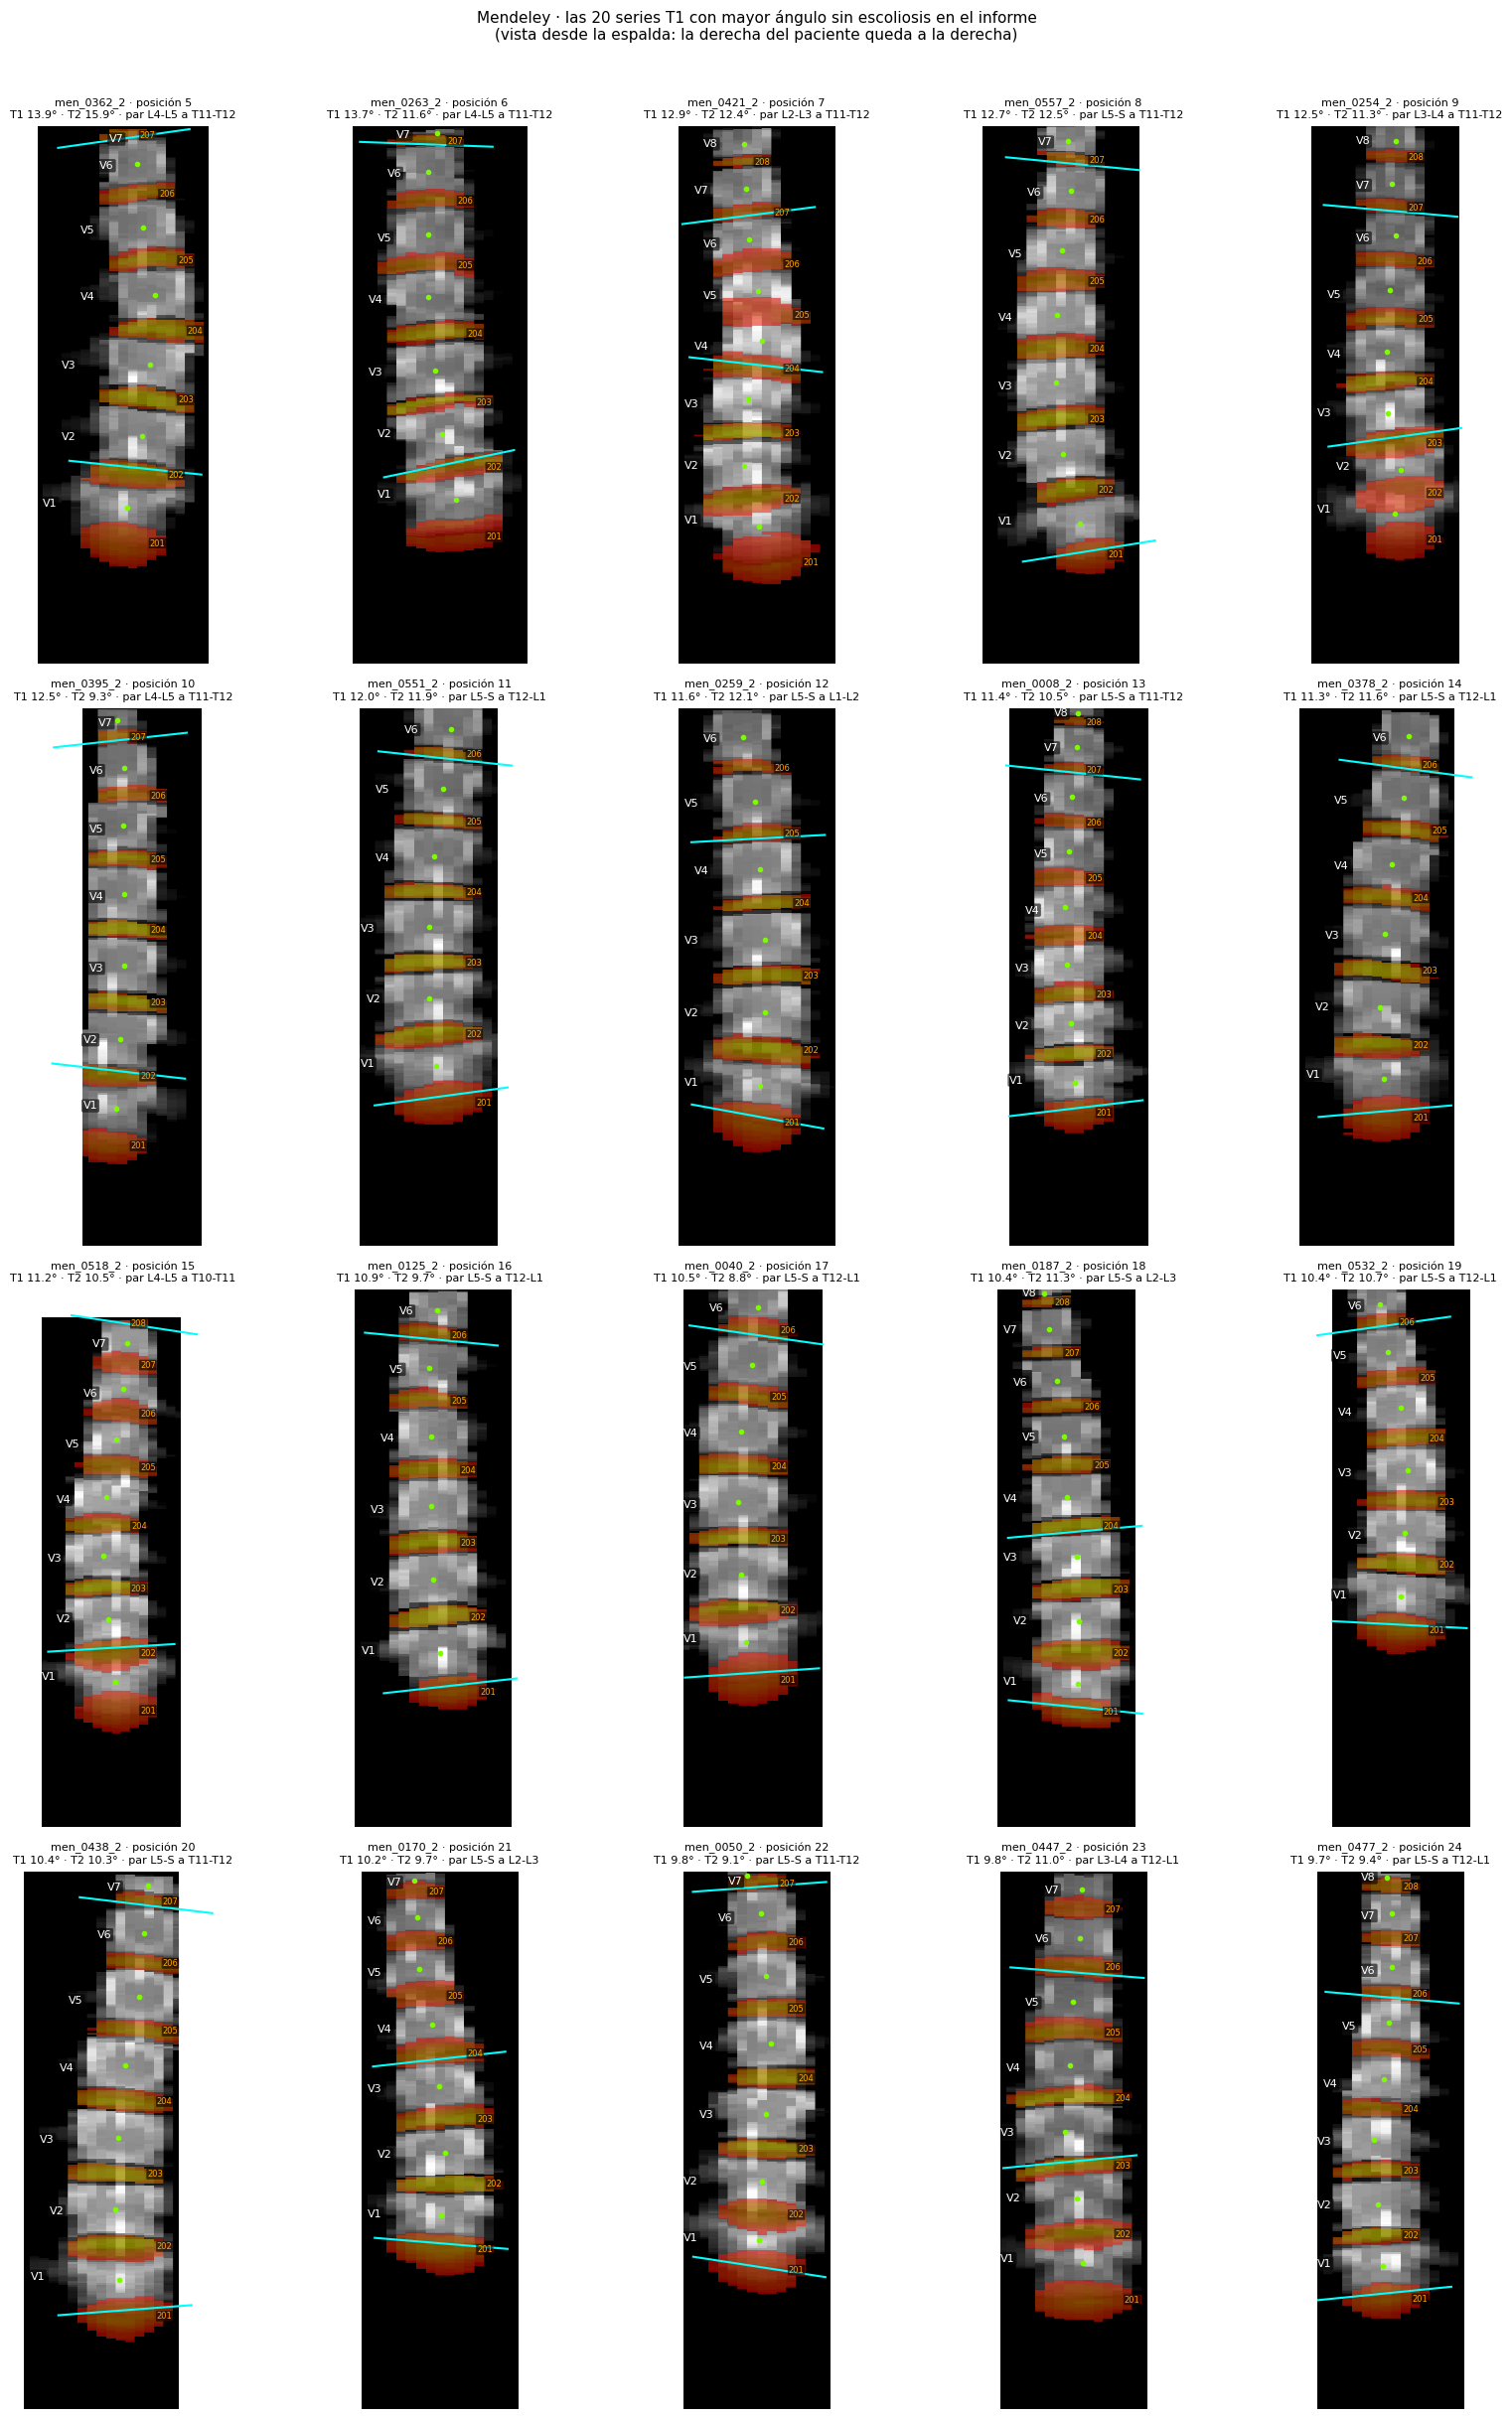

In [ ]:
# 4. Las 20 series T1 de Mendeley con mayor ángulo sin escoliosis en el informe: tabla y paneles
men = angulos[(angulos["conjunto"] == "mendeley") & (angulos["clase"] == "T1")].dropna(subset=[f"angulo_{PRINCIPAL}"]).copy()
men["posicion"] = men[f"angulo_{PRINCIPAL}"].rank(ascending=False, method="min").astype(int)
men["con_mencion"] = men["estudio"].isin(CASOS_INFORME)
t2 = angulos[(angulos["conjunto"] == "mendeley") & (angulos["clase"] == "T2")].set_index("estudio")[f"angulo_{PRINCIPAL}"]
men["angulo_T2"] = men["estudio"].map(t2)
men["par_elegido"] = [f"{NOMBRE_DISCO_TSS.get(tss_de_disco.get((i, int(a))), '?')} a {NOMBRE_DISCO_TSS.get(tss_de_disco.get((i, int(b))), '?')}"
                      if pd.notna(a) else "" for i, a, b in zip(men["id_serie"], men[f"disco_caudal_{PRINCIPAL}"], men[f"disco_craneal_{PRINCIPAL}"])]
marcas_t1 = marcas_serie.set_index("id_serie")
men["marcas_de_la_serie"] = [" ".join(m for m in ("no_utilizable", "menos_de_seis_discos", "inclinacion_sagital_mayor_30",
                                                    "disco_del_par_en_borde", "sexta_lumbar") if bool(marcas_t1.loc[i, m])) for i in men["id_serie"]]
revision = (men[~men["con_mencion"]].sort_values(f"angulo_{PRINCIPAL}", ascending=False).head(N_REVISION)
            [["id_serie", "estudio", "posicion", f"angulo_{PRINCIPAL}", "angulo_T2", "angulo_centroides", "n_discos", "par_elegido",
              "marcas_de_la_serie"]].rename(columns={f"angulo_{PRINCIPAL}": "angulo_T1"}))
revision.to_csv(DIR_SALIDA / "revision_visual_mendeley_tabla.csv", index=False)       # Mendeley es CC BY
display(revision.round(1))

columnas = 5
filas_fig = int(np.ceil(len(revision) / columnas))
fig, axes = plt.subplots(filas_fig, columnas, figsize=(3.4 * columnas, 6.2 * filas_fig), squeeze=False)
for ax in axes.ravel():
    ax.axis("off")
for ax, r in zip(axes.ravel(), revision.itertuples()):
    panel_de_serie(ax, r.id_serie, f"{r.id_serie} · posición {r.posicion}\nT1 {r.angulo_T1:.1f}° · T2 {r.angulo_T2:.1f}° · par {r.par_elegido}")
fig.suptitle(f"Mendeley · las {len(revision)} series T1 con mayor ángulo sin escoliosis en el informe\n"
             "(vista desde la espalda: la derecha del paciente queda a la derecha)", fontsize=11)
plt.tight_layout(rect=(0, 0, 1, 0.97))
fig.savefig(DIR_SALIDA / "revision_visual_mendeley_paneles.png", dpi=100, facecolor="white", bbox_inches="tight")
plt.show()

**Cómo leer la salida de la celda 4.** Cada fila corresponde a una de las 20 series seleccionadas. `posicion` indica el lugar que ocupa entre todas las series T1 de Mendeley, incluidos los estudios cuyos informes sí mencionan escoliosis; la posición 1 corresponde al ángulo más alto. `angulo_T2` muestra el resultado de la otra secuencia del mismo estudio y permite comprobar si la magnitud de la curvatura se mantiene entre T1 y T2. Una diferencia pequeña no demuestra que la segmentación sea correcta, pero una discrepancia puede señalar un caso que conviene revisar.

`par_elegido` identifica los discos entre cuyas caras se calcula el ángulo, con sus nombres anatómicos. `marcas_de_la_serie` recoge las observaciones de calidad registradas en el cuaderno 10. En los paneles, las líneas cian representan las caras del par seleccionado y los puntos verdes corresponden a los centroides de los cuerpos vertebrales. La imagen se muestra desde la espalda del paciente, siguiendo la orientación utilizada en la figura del script.

La revisión debe considerar si la columna presenta una curvatura visible, si las caras del par elegido tienen una orientación anatómicamente razonable y si las etiquetas están ubicadas sobre las estructuras que les corresponden.


In [ ]:
# 5. Juicio de la revisión visual (lo escribe el analista después de mirar los paneles)
# Una entrada por serie: "curva", "error de segmentación" o "dudoso", y un comentario corto si hace falta.
REVISION_VISUAL = {
    "men_0362_2": ("curva", "correcta segmentación"),
    "men_0263_2": ("error de segmentación", "mal centroide v7, inclinación de más v7"),
    "men_0421_2": ("dudoso", "doble ángulo presente de v4-v7, v1-v4"),
    "men_0557_2": ("curva", "correcta segmentación"),
    "men_0254_2": ("curva", "correcta segmentación"),
    "men_0395_2": ("dudoso", "disco del par en el borde, v7, todas las vértebras cortadas"),
    "men_0551_2": ("curva", "correcta segmentación"),
    "men_0259_2": ("curva", "correcta segmentación"),
    "men_0008_2": ("error de segmentación", " v2-v5 o v6"),
    "men_0378_2": ("curva", "correcta segmentación"),
    "men_0518_2": ("error de segmentación", "v2-v7 (207)"),
    "men_0125_2": ("curva", "correcta segmentación"),
    "men_0040_2": ("curva", "correcta segmentación"),
    "men_0187_2": ("dudoso", "v6 a v8 cortadas, 202-204"),
    "men_0532_2": ("curva", "correcta segmentación"),
    "men_0438_2": ("dudoso", "v6, v7 tocando el borde pero está bien segmentado"),
    "men_0170_2": ("dudoso", "v5 a v7 cortadas o tocando borde, correcta segmentación"),
    "men_0050_2": ("curva", "correcta segmentación"),
    "men_0447_2": ("curva", "correcta segmentación"),
    "men_0477_2": ("curva", "correcta segmentación"),
}
juicio = revision[["id_serie", "posicion", "angulo_T1", "angulo_T2"]].copy()
juicio["juicio"] = juicio["id_serie"].map(lambda i: REVISION_VISUAL.get(i, ("sin revisar", ""))[0])
juicio["comentario"] = juicio["id_serie"].map(lambda i: REVISION_VISUAL.get(i, ("", ""))[1])
assert set(juicio["juicio"]) <= {"curva", "error de segmentación", "dudoso", "sin revisar"}, "Juicio no reconocido"
juicio.to_csv(DIR_SALIDA / "revision_visual_mendeley_juicio.csv", index=False)
print("Resumen de la revisión visual:", juicio["juicio"].value_counts().to_dict())
display(juicio)

Resumen de la revisión visual: {'curva': 12, 'dudoso': 5, 'error de segmentación': 3}


,id_serie,posicion,angulo_T1,angulo_T2,juicio,comentario
232,men_0362_2,5,13.938646,15.947248,curva,correcta segmentación
272,men_0263_2,6,13.738349,11.559684,error de segmentación,"mal centroide v7, inclinación de más v7"
128,men_0421_2,7,12.925106,12.350874,dudoso,"doble ángulo presente de v4-v7, v1-v4"
70,men_0557_2,8,12.681662,12.482308,curva,correcta segmentación
405,men_0254_2,9,12.545785,11.341519,curva,correcta segmentación
443,men_0395_2,10,12.502326,9.320059,dudoso,"disco del par en el borde, v7, todas las vérte..."
403,men_0551_2,11,12.013872,11.925309,curva,correcta segmentación
427,men_0259_2,12,11.556811,12.083436,curva,correcta segmentación
2636,men_0008_2,13,11.377259,10.464653,error de segmentación,v2-v5 o v6
2578,men_0378_2,14,11.310513,11.558803,curva,correcta segmentación


**Cómo leer la salida de la celda 5.** El resumen cuenta cuántas de las 20 series se clasificaron como curva, error de segmentación o dudoso. Si `REVISION_VISUAL` no contiene una valoración para alguna serie, esta aparece como «sin revisar». En la ejecución archivada, las 20 series tienen una clasificación: 12 se consideraron curvas con segmentación correcta, 3 presentaron errores de segmentación y 5 quedaron como dudosas.

La clasificación es una valoración visual individual, no una referencia clínica ni una evaluación independiente de la calidad de la máscara. Por eso debe interpretarse como una revisión exploratoria de los casos seleccionados.


## El par elegido y el ángulo lumbar

En el cuaderno 10, el ángulo se calculó utilizando todos los discos visibles en cada serie, incluidos los torácicos y, cuando aparecen, los cervicales que entran en el campo de visión. Como consecuencia, el par que determina el máximo puede abarcar niveles distintos según la cobertura de la imagen. Dos series de un mismo estudio también pueden terminar utilizando pares diferentes.

Esta variación podría contribuir a las diferencias observadas entre RSNA y Mendeley. La celda 6 describe los niveles que forman el par elegido, cuantifica cuántos discos torácicos o cervicales aparecen en el campo y vuelve a calcular el ángulo restringiendo la selección a los discos lumbares definidos por las etiquetas de TotalSpineSeg. Finalmente, compara el acuerdo T1–T2 del ángulo lumbar con el obtenido al utilizar todos los discos, mediante las mismas medidas del análisis 1 del cuaderno 10.


In [ ]:
# 6. Discos del par elegido, discos torácicos en el campo y ángulo restringido a los discos lumbares
filas = []
for i, c in caras.groupby("id_serie"):
    lumbares = c[c["disco_tss"].isin(DISCOS_LUMBARES_TSS)]
    fila = {"id_serie": i, "discos_toracicos_o_cervicales": int(c.loc[c["disco_tss"] < 91, "disco"].nunique()),
            "discos_lumbares": int(lumbares["disco"].nunique())}
    for f, col in F_CORTO.items():
        ang, a, b = regla_articulo(tabla_de_caras(lumbares, col)) if lumbares["disco"].nunique() >= 2 else (np.nan, np.nan, np.nan)
        fila[f"angulo_lumbar_{f}"] = ang
    filas.append(fila)
lumbar = angulos.merge(pd.DataFrame(filas), on="id_serie", how="left")
lumbar["nivel_caudal"] = [tss_de_disco.get((i, int(a))) if pd.notna(a) else np.nan
                          for i, a in zip(lumbar["id_serie"], lumbar[f"disco_caudal_{PRINCIPAL}"])]
lumbar["nivel_craneal"] = [tss_de_disco.get((i, int(b))) if pd.notna(b) else np.nan
                           for i, b in zip(lumbar["id_serie"], lumbar[f"disco_craneal_{PRINCIPAL}"])]
lumbar["par_con_disco_toracico"] = lumbar["nivel_craneal"] < 91
lumbar["par_con_L5_S"] = lumbar["nivel_caudal"] == 100
lumbar.to_csv(DIR_PRIV / "angulo_lumbar_por_serie.csv", index=False)
lumbar[lumbar["conjunto"] == "mendeley"].to_csv(DIR_SALIDA / "angulo_lumbar_por_serie_mendeley.csv", index=False)

t1 = lumbar[(lumbar["clase"] == "T1") & lumbar[f"angulo_{PRINCIPAL}"].notna()]
filas = []
for conjunto, g in t1.groupby("conjunto"):
    g_l = g.dropna(subset=[f"angulo_lumbar_{PRINCIPAL}"])
    completo, solo_lumbar = proporcion(g[f"angulo_{PRINCIPAL}"] >= UMBRAL_ANGULO), proporcion(g_l[f"angulo_lumbar_{PRINCIPAL}"] >= UMBRAL_ANGULO)
    altos = g[g[f"angulo_{PRINCIPAL}"] >= UMBRAL_ANGULO]
    filas.append({"conjunto": CONJUNTOS[conjunto], "series_T1": len(g),
                  "con_algun_disco_toracico_pct": 100 * (g["discos_toracicos_o_cervicales"] > 0).mean(),
                  "discos_toracicos_mediana": g["discos_toracicos_o_cervicales"].median(),
                  "par_con_L5_S_pct": 100 * g["par_con_L5_S"].mean(),
                  "par_con_disco_toracico_pct": 100 * g["par_con_disco_toracico"].mean(),
                  "par_con_disco_toracico_entre_ge10_pct": 100 * altos["par_con_disco_toracico"].mean() if len(altos) else np.nan,
                  "ge10_todos_los_discos_pct": completo["pct"], "ge10_todos_ic95": f"{completo['ic95_inf_pct']:.1f}–{completo['ic95_sup_pct']:.1f}",
                  "ge10_solo_lumbar_pct": solo_lumbar["pct"], "ge10_solo_lumbar_ic95": f"{solo_lumbar['ic95_inf_pct']:.1f}–{solo_lumbar['ic95_sup_pct']:.1f}",
                  "series_con_angulo_lumbar": len(g_l),
                  "mediana_todos": g[f"angulo_{PRINCIPAL}"].median(), "mediana_lumbar": g_l[f"angulo_lumbar_{PRINCIPAL}"].median()})
resumen_par = pd.DataFrame(filas).set_index("conjunto")
resumen_par.to_csv(DIR_SALIDA / "par_elegido_y_angulo_lumbar_resumen.csv")
display(resumen_par.round(1).T)

niveles = (t1.assign(par=[f"{NOMBRE_DISCO_TSS.get(a, '?')} a {NOMBRE_DISCO_TSS.get(b, '?')}" for a, b in zip(t1["nivel_caudal"], t1["nivel_craneal"])])
           .groupby("conjunto")["par"].value_counts(normalize=True).mul(100).rename("pct").reset_index())
niveles = niveles[niveles.groupby("conjunto")["pct"].rank(ascending=False, method="first") <= 8]
niveles.to_csv(DIR_SALIDA / "par_elegido_niveles_frecuentes.csv", index=False)
print("Pares más frecuentes en la T1 (% de series):")
display(niveles.pivot_table(index="par", columns="conjunto", values="pct").rename(columns=CONJUNTOS).round(1)
        .sort_values("Mendeley", ascending=False))

por_toracicos = (t1.assign(toracicos=t1["discos_toracicos_o_cervicales"].clip(upper=3).map(lambda v: "3 o más" if v == 3 else str(int(v))))
                 .groupby(["conjunto", "toracicos"])
                 .agg(series=("id_serie", "size"), mediana=(f"angulo_{PRINCIPAL}", "median"),
                      ge10_pct=(f"angulo_{PRINCIPAL}", lambda x: 100 * (x >= UMBRAL_ANGULO).mean()),
                      ge10_lumbar_pct=(f"angulo_lumbar_{PRINCIPAL}", lambda x: 100 * (x.dropna() >= UMBRAL_ANGULO).mean())))
por_toracicos.to_csv(DIR_SALIDA / "angulo_segun_discos_toracicos.csv")
print("Ángulo de la T1 según el número de discos torácicos o cervicales en el campo:")
display(por_toracicos.round(1))

ancho = por_estudio(lumbar, [f"angulo_lumbar_{PRINCIPAL}", f"angulo_{PRINCIPAL}"])
filas = []
for conjunto in CONJUNTOS:
    t = ancho.loc[conjunto].dropna()
    for nombre, col in (("todos los discos (cuaderno 10)", f"angulo_{PRINCIPAL}"), ("solo lumbar", f"angulo_lumbar_{PRINCIPAL}")):
        filas.append({"conjunto": CONJUNTOS[conjunto], "angulo": nombre, **acuerdo(t[f"{col}_T1"], t[f"{col}_T2"])})
acuerdo_lumbar = pd.DataFrame(filas)
acuerdo_lumbar.to_csv(DIR_SALIDA / "angulo_lumbar_acuerdo_t1_t2.csv", index=False)
print("Acuerdo T1–T2, mismos estudios con los dos ángulos (conjunto completo):")
display(acuerdo_lumbar.round(3))

conjunto,Mendeley,RSNA
series_T1,515,1972
con_algun_disco_toracico_pct,69.9,90.9
discos_toracicos_mediana,1.0,1.0
par_con_L5_S_pct,51.1,38.9
par_con_disco_toracico_pct,26.2,41.3
par_con_disco_toracico_entre_ge10_pct,52.4,43.8
ge10_todos_los_discos_pct,4.1,15.1
ge10_todos_ic95,2.5–6.2,13.5–16.7
ge10_solo_lumbar_pct,3.5,12.3
ge10_solo_lumbar_ic95,2.1–5.5,10.9–13.9


Pares más frecuentes en la T1 (% de series):


conjunto,Mendeley,RSNA
par,,
L5-S a T12-L1,13.0,NaN
L4-L5 a T12-L1,11.3,7.2
L5-S a L2-L3,10.9,8.7
L5-S a L1-L2,9.7,6.3
L5-S a T11-T12,8.0,6.6
L4-L5 a T11-T12,8.0,7.6
L5-S a L3-L4,7.0,6.9
L3-L4 a T12-L1,6.0,NaN
L3-L4 a T11-T12,NaN,6.9


Ángulo de la T1 según el número de discos torácicos o cervicales en el campo:


series  mediana  ge10_pct  ge10_lumbar_pct
conjunto toracicos                                            
mendeley 0             155      3.5       3.9              3.9
         1             309      4.3       2.3              1.3
         2              45      5.5      11.1             11.1
         3 o más         6     11.1      50.0             50.0
rsna     0             180      4.2       5.6              5.6
         1             998      5.0      11.5              9.7
         2             620      5.9      21.1             17.1
         3 o más       174      6.5      23.6             17.2

Acuerdo T1–T2, mismos estudios con los dos ángulos (conjunto completo):


,conjunto,angulo,estudios,sesgo,sesgo_ic95_inf,sesgo_ic95_sup,ancho_limites,ancho_limites_ic95_inf,ancho_limites_ic95_sup,icc_a1,icc_a1_ic95_inf,icc_a1_ic95_sup
0,Mendeley,todos los discos (cuaderno 10),509,-0.002,-0.072,0.069,3.250,2.939,3.603,0.957,0.931,0.972
1,Mendeley,solo lumbar,509,-0.020,-0.079,0.045,2.846,2.623,3.077,0.964,0.943,0.976
2,RSNA,todos los discos (cuaderno 10),1970,-0.096,-0.142,-0.051,3.940,3.715,4.152,0.978,0.973,0.982
3,RSNA,solo lumbar,1970,-0.011,-0.048,0.027,3.323,3.160,3.489,0.982,0.979,0.985


**Cómo leer la salida de la celda 6.** La primera tabla está traspuesta y presenta una columna para cada conjunto. Las primeras filas indican qué porcentaje de las series T1 contiene al menos un disco torácico o cervical y cuál es la mediana de discos de esos niveles incluidos en el campo de visión. Las filas siguientes describen el par elegido: muestran con qué frecuencia su cara caudal corresponde a L5-S, con qué frecuencia su cara craneal pertenece a un disco torácico o cervical y qué proporción presenta esta última característica entre las series cuyo ángulo alcanza 10° o más.

Las últimas filas comparan la proporción de series con ángulos de 10° o más cuando se utilizan todos los discos y cuando el cálculo se restringe a los niveles lumbares. Se presentan los intervalos de confianza del 95 % de Clopper-Pearson. Si la diferencia entre RSNA y Mendeley disminuyera considerablemente al restringir el cálculo, eso indicaría que la selección de discos torácicos o cervicales contribuye a la diferencia entre conjuntos.

La segunda tabla muestra los pares de niveles más frecuentes. La tercera agrupa las series según el número de discos torácicos o cervicales incluidos en el campo y presenta la mediana del ángulo y la proporción de resultados de 10° o más, tanto con todos los discos como con el cálculo lumbar. La cuarta tabla compara el acuerdo T1–T2 de ambas definiciones del ángulo sobre los mismos estudios. Esta última permite evaluar si la restricción lumbar modifica la concordancia entre secuencias.


## Marcas y curvatura

En el cuaderno 10, dos de los cinco pacientes de Mendeley cuyos informes mencionaban escoliosis tenían marcas de calidad asociadas a la máscara no utilizable y al disco del par elegido situado en el borde. Esto plantea la posibilidad de que algunas marcas aparezcan precisamente en estudios con curvaturas más pronunciadas.

La celda 7 compara, para cada marca y conjunto, la proporción de estudios con ángulos T1 de 10° o más y la mediana del ángulo entre los estudios que presentan la marca y los que no. También identifica las marcas registradas en los cinco pacientes de Mendeley con mención de escoliosis. Estas comparaciones describen asociaciones; no permiten establecer si una marca causa un error de medición, si aparece como consecuencia de la curvatura o si ambas dependen de otra característica de la adquisición.


In [ ]:
# 7. ¿Qué marcas aparecen con más frecuencia en los ángulos grandes?
t1_estudio = angulos[angulos["clase"] == "T1"].set_index(["conjunto", "estudio"])[f"angulo_{PRINCIPAL}"]
m = marcas_estudio.join(t1_estudio.rename("angulo_T1"), how="inner").dropna(subset=["angulo_T1"])
filas = []
for conjunto, g in m.groupby(level="conjunto"):
    for marca in MARCAS:
        con, sin = g[g[marca].astype(bool)], g[~g[marca].astype(bool)]
        filas.append({"conjunto": CONJUNTOS[conjunto], "marca": marca, "estudios_con_marca": len(con),
                      "ge10_con_marca_pct": 100 * (con["angulo_T1"] >= UMBRAL_ANGULO).mean() if len(con) else np.nan,
                      "ge10_sin_marca_pct": 100 * (sin["angulo_T1"] >= UMBRAL_ANGULO).mean() if len(sin) else np.nan,
                      "mediana_con_marca": con["angulo_T1"].median(), "mediana_sin_marca": sin["angulo_T1"].median(),
                      "pct_de_los_ge10_con_esta_marca": 100 * g.loc[g["angulo_T1"] >= UMBRAL_ANGULO, marca].astype(bool).mean()})
marcas_y_angulo = pd.DataFrame(filas)
marcas_y_angulo.to_csv(DIR_SALIDA / "marcas_y_curvatura.csv", index=False)
display(marcas_y_angulo.round(1))

casos = marcas_estudio.loc["mendeley"].reindex(sorted(CASOS_INFORME))[MARCAS]
casos.to_csv(DIR_SALIDA / "marcas_de_los_casos_con_informe.csv")
print("Marcas de los pacientes de Mendeley con escoliosis en el informe:")
display(casos)

,conjunto,marca,estudios_con_marca,ge10_con_marca_pct,ge10_sin_marca_pct,mediana_con_marca,mediana_sin_marca,pct_de_los_ge10_con_esta_marca
0,Mendeley,no_utilizable,37,16.2,3.1,5.4,4.0,28.6
1,Mendeley,menos_de_seis_discos,8,0.0,4.1,4.2,4.1,0.0
2,Mendeley,inclinacion_sagital_mayor_30,123,1.6,4.8,4.1,4.1,9.5
3,Mendeley,disco_del_par_en_borde,38,18.4,2.9,4.8,4.0,33.3
4,Mendeley,sexta_lumbar,2,0.0,4.1,4.8,4.1,0.0
5,Mendeley,numeracion_t1_t2_distinta,4,0.0,4.1,4.4,4.1,0.0
6,RSNA,no_utilizable,233,18.5,14.6,5.7,5.2,14.5
7,RSNA,menos_de_seis_discos,0,NaN,15.1,NaN,5.3,0.0
8,RSNA,inclinacion_sagital_mayor_30,505,7.9,17.5,5.1,5.4,13.5
9,RSNA,disco_del_par_en_borde,206,15.5,15.0,5.5,5.2,10.8


Marcas de los pacientes de Mendeley con escoliosis en el informe:


,no_utilizable,menos_de_seis_discos,inclinacion_sagital_mayor_30,disco_del_par_en_borde,sexta_lumbar,numeracion_t1_t2_distinta
estudio,,,,,,
0091,False,False,False,False,False,False
0196,False,False,False,False,False,False
0197,False,False,False,False,False,False
0230,True,False,False,True,False,False
0401,True,False,False,True,False,False


**Cómo leer la salida de la celda 7.** Cada fila compara, dentro de un conjunto, los estudios que presentan una marca con aquellos que no la tienen. `ge10_con_marca_pct` y `ge10_sin_marca_pct` indican el porcentaje de estudios con un ángulo T1 de 10° o más en cada grupo. `mediana_con_marca` y `mediana_sin_marca` muestran las medianas correspondientes. Por su parte, `pct_de_los_ge10_con_esta_marca` indica qué proporción de todos los estudios con ángulos de 10° o más presenta esa marca.

Una diferencia marcada entre ambos grupos indica que la marca está asociada con la distribución de los ángulos en ese conjunto. No demuestra que la medición sea incorrecta. Por eso, excluir automáticamente todos los estudios que presentan una marca podría eliminar también curvas reales. La segunda tabla muestra las marcas de los cinco pacientes de Mendeley cuyos informes mencionan escoliosis.


## Spline frente a diferencias centrales

El estimador de centroides del cuaderno 10 calcula la tangente en cada vértebra interior mediante la recta que une los centroides de sus dos vértebras vecinas. Es un procedimiento sencillo y no requiere ajustar un parámetro, aunque puede ser sensible a las variaciones en la posición de los centroides. En el cuaderno 10 mostró un acuerdo T1–T2 inferior al obtenido con el ángulo calculado a partir de las caras de los discos.

La celda 8 evalúa una alternativa: ajustar un *spline* cúbico suavizado a los centroides en el plano coronal, representados como la función $x(z)$, y calcular la tangente a partir de su derivada en las mismas vértebras interiores. SciPy selecciona el parámetro de suavizado mediante validación cruzada generalizada (GCV), por lo que no se fija manualmente. El ajuste requiere al menos cinco vértebras; por ello, la comparación se realiza sobre los estudios que cuentan con un resultado para ambos estimadores.


In [ ]:
# 8. Estimador de centroides con spline cúbico suavizado frente a diferencias centrales
def angulo_spline(cent):
    "Mayor diferencia entre las tangentes del spline suavizado x(z), en las vértebras interiores (sin los extremos)."
    c = cent.sort_values("cz")
    if len(c) < 5 or not np.all(np.diff(c["cz"].to_numpy(float)) > 0):
        return np.nan
    z, x = c["cz"].to_numpy(float), c["cx"].to_numpy(float)
    try:
        s = make_smoothing_spline(z, x)
    except Exception:
        return np.nan
    t = np.degrees(np.arctan(s.derivative()(z[1:-1])))
    return float(t.max() - t.min())

filas = []
for i, c in centroides.groupby("id_serie"):
    filas.append({"id_serie": i, "angulo_spline": angulo_spline(c),
                  "angulo_centrales": angulo_por_centroides(c)[0], "vertebras": len(c)})
spl = angulos[["id_serie", "conjunto", "estudio", "clase", f"angulo_{PRINCIPAL}"]].merge(pd.DataFrame(filas), on="id_serie", how="left")
spl.to_csv(DIR_PRIV / "centroides_spline_por_serie.csv", index=False)
spl[spl["conjunto"] == "mendeley"].to_csv(DIR_SALIDA / "centroides_spline_por_serie_mendeley.csv", index=False)

ancho_s = por_estudio(spl, ["angulo_spline", "angulo_centrales", f"angulo_{PRINCIPAL}"])
filas, filas_rho = [], []
for conjunto in CONJUNTOS:
    t = ancho_s.loc[conjunto].dropna()
    for nombre, col in (("diferencias centrales", "angulo_centrales"), ("spline suavizado", "angulo_spline"),
                        ("caras de disco (eje lateral)", f"angulo_{PRINCIPAL}")):
        filas.append({"conjunto": CONJUNTOS[conjunto], "estimador": nombre, **acuerdo(t[f"{col}_T1"], t[f"{col}_T2"]),
                      "mediana_T1": t[f"{col}_T1"].median()})
    for nombre, col in (("diferencias centrales", "angulo_centrales"), ("spline suavizado", "angulo_spline")):
        filas_rho.append({"conjunto": CONJUNTOS[conjunto], "estimador": nombre, "estudios": len(t),
                          "spearman_con_caras_T1": stats.spearmanr(t[f"{col}_T1"], t[f"angulo_{PRINCIPAL}_T1"]).statistic})
spline_acuerdo = pd.DataFrame(filas)
spline_rho = pd.DataFrame(filas_rho)
spline_acuerdo.to_csv(DIR_SALIDA / "spline_frente_a_centrales_acuerdo.csv", index=False)
spline_rho.to_csv(DIR_SALIDA / "spline_frente_a_centrales_spearman.csv", index=False)
print("Series sin ángulo spline (menos de 5 vértebras o ajuste fallido):",
      spl[spl["angulo_centrales"].notna()].groupby("conjunto")["angulo_spline"].apply(lambda x: int(x.isna().sum())).to_dict())
print("Acuerdo T1–T2 de cada estimador, sobre los mismos estudios:")
display(spline_acuerdo.round(3))
print("Correlación de Spearman con el ángulo por caras de disco (T1):")
display(spline_rho.round(3))

Series sin ángulo spline (menos de 5 vértebras o ajuste fallido): {'mendeley': 0, 'rsna': 0}
Acuerdo T1–T2 de cada estimador, sobre los mismos estudios:


,conjunto,estimador,estudios,sesgo,sesgo_ic95_inf,sesgo_ic95_sup,ancho_limites,ancho_limites_ic95_inf,ancho_limites_ic95_sup,icc_a1,icc_a1_ic95_inf,icc_a1_ic95_sup,mediana_T1
0,Mendeley,diferencias centrales,508,0.142,-0.075,0.306,8.725,4.174,13.435,0.876,0.724,0.967,5.542
1,Mendeley,spline suavizado,508,0.048,-0.638,0.472,26.749,6.292,45.070,0.539,0.275,0.953,7.447
2,Mendeley,caras de disco (eje lateral),508,-0.001,-0.073,0.070,3.228,2.897,3.537,0.957,0.934,0.972,4.101
3,RSNA,diferencias centrales,1971,-0.108,-0.206,0.000,9.257,7.309,11.795,0.947,0.915,0.967,6.665
4,RSNA,spline suavizado,1971,-0.147,-0.351,0.080,19.255,10.776,28.243,0.853,0.728,0.948,8.721
5,RSNA,caras de disco (eje lateral),1971,-0.093,-0.140,-0.048,3.968,3.732,4.186,0.978,0.973,0.982,5.255


Correlación de Spearman con el ángulo por caras de disco (T1):


,conjunto,estimador,estudios,spearman_con_caras_T1
0,Mendeley,diferencias centrales,508,0.461
1,Mendeley,spline suavizado,508,0.405
2,RSNA,diferencias centrales,1971,0.696
3,RSNA,spline suavizado,1971,0.669


**Cómo leer la salida de la celda 8.** La primera línea informa cuántas series tienen un ángulo calculado por diferencias centrales, pero no por *spline*. En esta ejecución el resultado es cero tanto en Mendeley como en RSNA, por lo que no se perdió ninguna serie por falta de vértebras o por un ajuste fallido.

La primera tabla compara el acuerdo T1–T2 de los tres estimadores sobre los mismos estudios. Un menor ancho de los límites de acuerdo y un ICC(A,1) mayor indican mejor repetibilidad. La fila correspondiente a las caras de los discos sirve como referencia, porque ese fue el estimador más repetible en el cuaderno 10. `mediana_T1` permite observar que los estimadores no producen valores centrales de la misma magnitud; por eso, las diferencias entre los anchos de los límites deben interpretarse junto con el ICC y no de forma aislada.

La segunda tabla presenta la correlación de Spearman entre cada estimador de centroides y el ángulo por caras de disco en T1. Una correlación más alta indica una mayor asociación entre las ordenaciones de los estudios, pero no demuestra que ambos métodos midan exactamente lo mismo ni que uno sea más preciso.


## Síntesis

Los resultados de este cuaderno son exploratorios. Las preguntas surgieron después de examinar los resultados del cuaderno 10 y no formaban parte del análisis registrado. Por tanto, los hallazgos permiten identificar problemas y proponer decisiones para el trabajo posterior, pero no deben interpretarse como confirmaciones clínicas ni como conclusiones definitivas.

**Revisión visual de los ángulos más altos.** Las 20 series revisadas ocupan las posiciones 5 a 24 de la ordenación de Mendeley y presentan ángulos T1 entre 9,7° y 13,9°. La revisión visual clasificó 12 como curvas con segmentación aparentemente correcta, 3 como errores de segmentación (estudios 0263, 0008 y 0518) y 5 como dudosas. En cuatro de estas últimas había vértebras o discos que tocaban el borde del campo de visión o quedaban cortados por él, y la quinta mostraba dos tramos angulados. En conjunto, la mayoría de los ángulos altos sin mención de escoliosis en el informe correspondió a curvaturas visibles con una segmentación que el analista consideró correcta. Esto muestra que la ausencia de una mención en el informe no equivale a demostrar que la columna sea recta y limita el uso de esos informes como referencia negativa. Los tres errores también muestran que una medición automática necesita controles de calidad capaces de detectar situaciones como centroides mal ubicados o inclinaciones anómalas de los discos. La revisión fue realizada por una sola persona, sin cegamiento ni un segundo evaluador, por lo que la clasificación puede contener sesgo de observación.

**El par elegido y el ángulo lumbar.** El 90,9 % de las series T1 de RSNA y el 69,9 % de las de Mendeley contienen al menos un disco torácico o cervical en el campo de visión. La cara craneal del par elegido corresponde a uno de esos niveles en el 41,3 % de RSNA y el 26,2 % de Mendeley. Al restringir el cálculo a los discos lumbares definidos en el cuaderno, la proporción de ángulos de 10° o más disminuye de 4,1 % a 3,5 % en Mendeley (IC del 95 %: 2,1–5,5) y de 15,1 % a 12,3 % en RSNA (IC del 95 %: 10,9–13,9). La diferencia entre conjuntos se mantiene: la proporción de RSNA sigue siendo aproximadamente 3,5 veces la de Mendeley. Por tanto, la inclusión de discos torácicos o cervicales contribuye a modificar los resultados, pero no explica por sí sola la diferencia entre los conjuntos.

La proporción de ángulos de 10° o más también aumenta con el número de discos torácicos o cervicales incluidos en el campo de visión de RSNA, incluso al utilizar el ángulo lumbar: pasa de 5,6 % en las series sin esos discos a 17,2 % en las que contienen tres o más. En Mendeley la tendencia no es uniforme y el grupo con tres o más discos contiene solo seis series, por lo que su porcentaje es inestable. Estos resultados son compatibles con la relación entre cobertura de la imagen y magnitud del ángulo observada en el cuaderno 10, pero no permiten determinar si las columnas más curvadas motivan adquisiciones con campos más amplios o si intervienen diferencias entre pacientes, protocolos o centros.

El ángulo lumbar presenta un acuerdo T1–T2 algo más estrecho que el cálculo con todos los discos. El ancho de los límites de acuerdo pasa de 3,25° a 2,85° en Mendeley (IC del 95 % para el ángulo lumbar: 2,62–3,08) y de 3,94° a 3,32° en RSNA (IC del 95 %: 3,16–3,49). El ICC(A,1) también aumenta ligeramente, de 0,957 a 0,964 en Mendeley y de 0,978 a 0,982 en RSNA. En RSNA, el sesgo T2 − T1 pasa de −0,096° con todos los discos a −0,011° con el ángulo lumbar. Parte de la reducción del ancho puede deberse a que, al considerar menos discos, el máximo tiende a ser menor: las medianas pasan de 4,1° a 3,8° en Mendeley y de 5,3° a 4,7° en RSNA. El aumento del ICC apunta en la misma dirección, pero los intervalos de confianza se superponen y no se realizó una prueba formal de la diferencia entre estimadores. El ángulo lumbar queda como candidato para un estudio posterior, no como una definición ya validada; cualquier cambio deberá registrarse antes de la siguiente evaluación.

**Marcas y curvatura.** En Mendeley, las marcas `no_utilizable` y `disco_del_par_en_borde` aparecen con mayor frecuencia entre los estudios con ángulos grandes. La proporción de ángulos de 10° o más es 16,2 % entre los estudios con la primera marca, frente a 3,1 % entre los que no la tienen. Para la marca de borde, las proporciones son 18,4 % y 2,9 %, respectivamente. Además, un 33,3 % de los estudios Mendeley con ángulos de 10° o más presenta la marca de borde. Los pacientes 0230 y 0401, cuyos informes mencionan escoliosis, tienen ambas marcas.

Una posible explicación es la cobertura lateral más estrecha de Mendeley, de aproximadamente 53 a 72 mm según el análisis del cuaderno 10: una columna curvada puede quedar parcialmente fuera del campo. Esta interpretación es plausible, pero los datos no permiten establecer causalidad. En RSNA, la marca de borde apenas diferencia la proporción de ángulos de 10° o más (15,5 % con la marca frente a 15,0 % sin ella). La inclinación sagital superior a 30° muestra una asociación en sentido contrario: en Mendeley, la proporción es 1,6 % frente a 4,8 %, y en RSNA, 7,9 % frente a 17,5 %. En consecuencia, no conviene convertir estas marcas en criterios automáticos de exclusión sin revisar antes qué situación anatómica o técnica representan. En particular, sería útil distinguir entre un disco que simplemente toca el borde y otro cuya estructura queda cortada.

**Spline frente a diferencias centrales.** En esta ejecución no hubo series sin resultado de *spline*. Sin embargo, el suavizado no mejoró la repetibilidad del estimador de centroides. El ancho de los límites de acuerdo T1–T2 fue de 26,75° en Mendeley y 19,26° en RSNA, frente a 8,73° y 9,26° con diferencias centrales. El ICC(A,1) del *spline* fue 0,539 en Mendeley y 0,853 en RSNA, mientras que con diferencias centrales fue 0,876 y 0,947, respectivamente. El ángulo por caras de disco obtuvo los mejores valores de referencia: anchos de 3,23° y 3,97°, e ICC de 0,957 y 0,978. La correlación de Spearman con el ángulo por caras también fue menor para el *spline* que para las diferencias centrales: 0,405 frente a 0,461 en Mendeley y 0,669 frente a 0,696 en RSNA.

Los intervalos de confianza de los límites de acuerdo del *spline* son amplios, especialmente en Mendeley, por lo que la magnitud exacta de su variabilidad debe interpretarse con cautela. Una posible explicación es que la selección automática del suavizado mediante GCV resulte inestable con el número limitado de centroides disponible por serie, aunque este mecanismo no se evaluó directamente. Con los resultados actuales no se justifica adoptar el *spline* como sustituto de las diferencias centrales. Tampoco sería adecuado fijar manualmente el parámetro de suavizado después de observar estos resultados. El ángulo por caras de disco continúa siendo el estimador más repetible entre los tres comparados.

**Lo que pasa al cuaderno de cierre.** Los resultados dejan cuatro tareas para la siguiente etapa: desarrollar controles automáticos de calidad para detectar errores de segmentación, revisar la definición de la marca de borde, evaluar el ángulo lumbar como posible medida principal mediante un análisis registrado previamente y estudiar por qué las series con mayor cobertura craneal tienden a presentar ángulos más altos. Ninguna de estas decisiones debe considerarse cerrada únicamente con los análisis exploratorios de este cuaderno.


In [ ]:
# 9. LEEME.md de la carpeta de resultados
leeme = """# 11 · Exploración del ángulo coronal

Resultados de `notebooks/11_exploracion_angulo_coronal.ipynb`. Todo es exploratorio: las preguntas surgieron al ver los resultados
del cuaderno 10 (plan registrado en OSF, doi:10.17605/OSF.IO/KP5DU) y no forman parte de ese plan. Solo investigación; no es
para diagnóstico. Los términos de uso de RSNA prohíben redistribuir sus datos: aquí solo hay agregados de RSNA. Mendeley
(doi:10.17632/k57fr854j2.2) tiene licencia CC BY 4.0.

| Archivo | Qué contiene |
|-|-|
| `revision_visual_mendeley_tabla.csv`, `revision_visual_mendeley_paneles.png`, `revision_visual_mendeley_juicio.csv` | Las 20 series T1 de Mendeley con mayor ángulo sin escoliosis en el informe, sus paneles y el juicio visual |
| `par_elegido_y_angulo_lumbar_resumen.csv`, `par_elegido_niveles_frecuentes.csv`, `angulo_segun_discos_toracicos.csv`, `angulo_lumbar_acuerdo_t1_t2.csv`, `angulo_lumbar_por_serie_mendeley.csv` | Discos del par elegido, discos torácicos en el campo y ángulo restringido a T12-L1 hasta L5-S |
| `marcas_y_curvatura.csv`, `marcas_de_los_casos_con_informe.csv` | Marcas de calidad frente al tamaño del ángulo |
| `spline_frente_a_centrales_acuerdo.csv`, `spline_frente_a_centrales_spearman.csv`, `centroides_spline_por_serie_mendeley.csv` | Estimador de centroides con spline suavizado frente a diferencias centrales |
| `entorno.json` | Versiones, parámetros y huellas de las entradas |
"""
(DIR_SALIDA / "LEEME.md").write_text(leeme, encoding="utf-8")
print(leeme)

# 11 · Exploración del ángulo coronal

Resultados de `notebooks/11_exploracion_angulo_coronal.ipynb`. Todo es exploratorio: las preguntas surgieron al ver los resultados
del cuaderno 10 (plan registrado en OSF, doi:10.17605/OSF.IO/KP5DU) y no forman parte de ese plan. Solo investigación; no es
para diagnóstico. Los términos de uso de RSNA prohíben redistribuir sus datos: aquí solo hay agregados de RSNA. Mendeley
(doi:10.17632/k57fr854j2.2) tiene licencia CC BY 4.0.

| Archivo | Qué contiene |
|-|-|
| `revision_visual_mendeley_tabla.csv`, `revision_visual_mendeley_paneles.png`, `revision_visual_mendeley_juicio.csv` | Las 20 series T1 de Mendeley con mayor ángulo sin escoliosis en el informe, sus paneles y el juicio visual |
| `par_elegido_y_angulo_lumbar_resumen.csv`, `par_elegido_niveles_frecuentes.csv`, `angulo_segun_discos_toracicos.csv`, `angulo_lumbar_acuerdo_t1_t2.csv`, `angulo_lumbar_por_serie_mendeley.csv` | Discos del par elegido, discos torácicos en el campo y ángulo restringi

In [ ]:
# 10. Registro del entorno
import sys, platform, importlib.metadata as md_
def version_de(p):
    try:
        return md_.version(p)
    except md_.PackageNotFoundError:
        return None
def sha256_archivo(ruta, bloque=1 << 20):
    h = hashlib.sha256()
    with open(ruta, "rb") as f:
        for trozo in iter(lambda: f.read(bloque), b""):
            h.update(trozo)
    return h.hexdigest()
entorno = {
    "fecha": datetime.datetime.now().isoformat(timespec="seconds"),
    "python": sys.version.split()[0], "plataforma": platform.platform(),
    "paquetes": {p: version_de(p) for p in ("numpy", "pandas", "scipy", "SimpleITK", "matplotlib", "tiger")},
    "parametros": {"bootstrap": B_BOOTSTRAP, "semilla": SEMILLA, "umbral_angulo": UMBRAL_ANGULO, "n_revision": N_REVISION,
                   "discos_lumbares_tss": sorted(DISCOS_LUMBARES_TSS), "spline": "scipy make_smoothing_spline, lam por GCV",
                   "formula": PRINCIPAL},
    "revision_visual": {k: list(v) for k, v in REVISION_VISUAL.items()},
    "entradas_sha256": {p.name: sha256_archivo(p) for p in (DIR_PRIV_10 / "angulos_por_serie.csv", DIR_PRIV_10 / "planos_por_cara.csv",
                                                            DIR_PRIV_10 / "centroides_por_vertebra.csv", DIR_PRIV_10 / "marcas_por_serie.csv",
                                                            DIR_PRIV_10 / "marcas_por_estudio.csv", DIR_PRIV_09 / "traduccion_etiquetas.csv",
                                                            CSV_MENCIONES_MENDELEY)},
}
(DIR_SALIDA / "entorno.json").write_text(json.dumps(entorno, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print(json.dumps({k: v for k, v in entorno.items() if k != "entradas_sha256"}, indent=2, ensure_ascii=False, default=str))

{
  "fecha": "2026-11-02T06:08:36",
  "python": "3.13.18",
  "plataforma": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "paquetes": {
    "numpy": "2.5.4",
    "pandas": "2.2.3",
    "scipy": "1.18.1",
    "SimpleITK": "2.5.7",
    "matplotlib": "3.10.0",
    "tiger": "6.3.0"
  },
  "parametros": {
    "bootstrap": 2000,
    "semilla": 2026,
    "umbral_angulo": 10.0,
    "n_revision": 20,
    "discos_lumbares_tss": [
      91,
      92,
      93,
      94,
      95,
      96,
      100
    ],
    "spline": "scipy make_smoothing_spline, lam por GCV",
    "formula": "eje_lateral"
  },
  "revision_visual": {
    "men_0362_2": [
      "curva",
      "correcta segmentación"
    ],
    "men_0263_2": [
      "error de segmentación",
      "mal centroide v7, inclinación de más v7"
    ],
    "men_0421_2": [
      "dudoso",
      "doble ángulo presente de v4-v7, v1-v4"
    ],
    "men_0557_2": [
      "curva",
      "correcta segmentación"
    ],
    "men_0254_2": [
      "curva",
      "correcta